[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D2_C6_NB11_neural_network_surrogates.ipynb)

# Day 2 · Chapter 6 · Notebook 11 — Neural networks as surrogate brains

**Goal.** All the models so far were built from the bottom up: neurons → populations → connectome. Here we go the other
way: we let an **artificial neural network (ANN)** learn the dynamics of a brain directly from its activity, and then use
the trained network as a **surrogate brain** that we can perturb (Luo et al. 2025, *Nature Methods*).

1. What is an artificial neural network, and how does it learn?
2. Neural Perturbational Inference (NPI): train an ANN on brain activity, perturb it, read out *effective connectivity*.
   We test it on our own model brain (NB09), where we know the true wiring.
3. Results on real human brains: personalised surrogate brains of 100 HCP participants tell us **where, when and how** to
   stimulate (Rabuffo, Acero-Pousa, Berjaga-Buisan & Deco 2026).

In [1]:
# --- Setup (run once) -------------------------------------------------------
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules and not os.path.exists("brain-modeling-course"):
    !git clone -q https://github.com/grabuffo/brain-modeling-course.git
    %cd brain-modeling-course/notebooks
    !pip -q install numba ipywidgets
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
import torch, torch.nn as nn
from IPython.display import Image, display
from src import connectome
torch.manual_seed(0)
PAPER = "../figures/paper" 

## 1. An artificial neural network in one slide

An artificial "neuron" computes a weighted sum of its inputs and passes it through a simple nonlinearity, e.g. the
**ReLU**, $\max(0,\cdot)$:
$$ y = \max\Big(0,\ \sum_k w_k x_k + b\Big). $$
A **network** stacks layers of such units. The weights $w$ start random and are **learned**: we show the network examples
(input, desired output), measure the error, and change every weight a little in the direction that reduces the error
(*gradient descent*, the same idea as the Euler step of NB00b, but in the space of weights). Repeat thousands of times.

Nothing biological is assumed: the network is a flexible function that can approximate (almost) any input–output relation.
Example: learn $y=\sin x$ from 200 noisy examples with one hidden layer of 30 units.

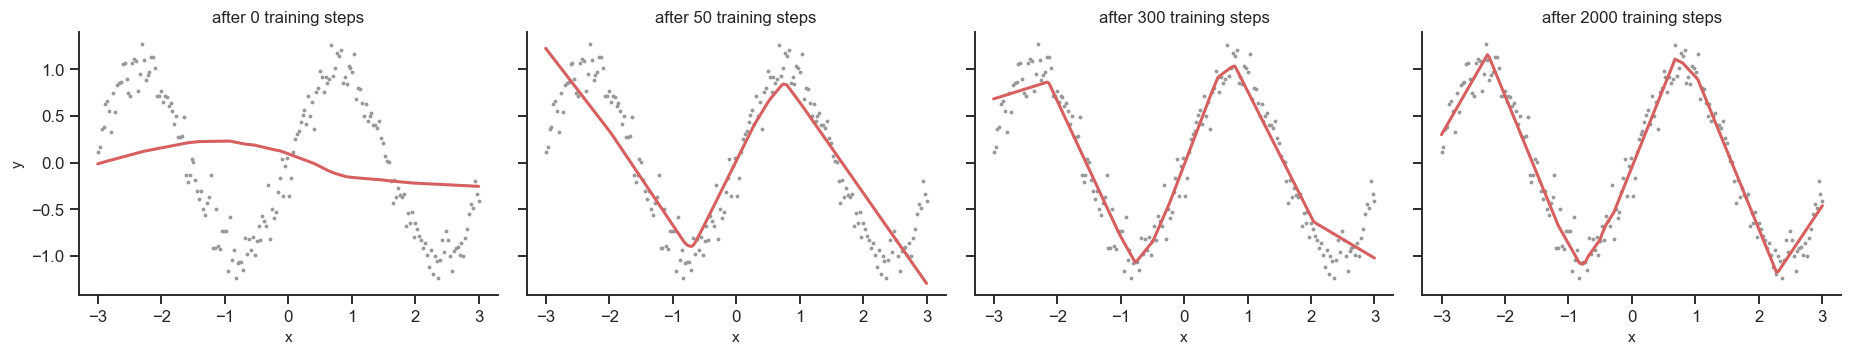

In [2]:
x = torch.linspace(-3, 3, 200).unsqueeze(1)
y = torch.sin(2 * x) + 0.15 * torch.randn_like(x)
net = nn.Sequential(nn.Linear(1, 30), nn.ReLU(), nn.Linear(30, 1))
opt = torch.optim.Adam(net.parameters(), lr=0.01)
fig, ax = plt.subplots(1, 4, figsize=(17, 3.4), sharey=True)
snap = {0: ax[0], 50: ax[1], 300: ax[2], 2000: ax[3]}
losses = []
for step in range(2001):
    if step in snap:
        with torch.no_grad():
            snap[step].plot(x, y, ".", c="0.6", ms=3); snap[step].plot(x, net(x), "C3", lw=2)
            snap[step].set(title=f"after {step} training steps", xlabel="x")
    loss = ((net(x) - y) ** 2).mean()
    opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
ax[0].set_ylabel("y")
plt.tight_layout()

The network starts as a random function (left) and, by reducing the prediction error step by step, ends up describing the
data (right). It has 91 parameters and no idea what a sine is.

## 2. A surrogate brain: Neural Perturbational Inference (NPI)

Luo et al. (2025) proposed to train an ANN to **predict the next fMRI frame** of the whole brain from the previous few frames:
$$ \mathbf{x}(t+1) \approx \mathrm{ANN}\big(\mathbf{x}(t-2), \mathbf{x}(t-1), \mathbf{x}(t)\big). $$
Once trained, the ANN is a surrogate of the brain's dynamics, and we can do what we cannot do in a person: **perturb**
one region at a time (add a small increment to its activity in the input) and see how the predicted next frame changes in
every other region. The average change, region $j$ → region $i$, is the **effective connectivity** (EC): a directed map of
who influences whom.

A method that claims to recover connectivity must first be tested where the answer is known. We do it twice, on the mouse
connectome (whose true wiring we know):

1. a simple **linear noisy network** on the connectome, $\dot x_i = -x_i + G\sum_j W_{ij}x_j + \text{noise}$, where every
   connection continuously transmits activity;
2. our **bistable whole-brain model** of NB09, seen through BOLD.

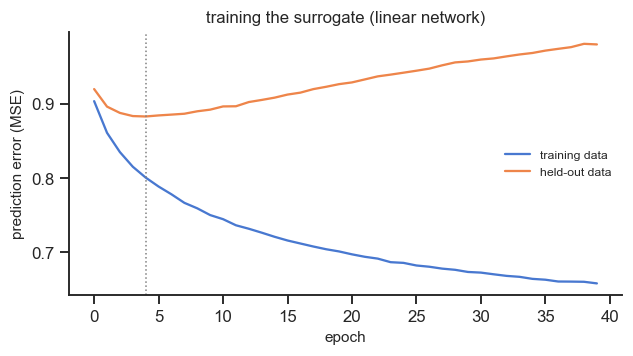

In [3]:
from scipy.stats import spearmanr
sc, labels, centres, fmri_regions = connectome.load_mouse()
N = sc.shape[0]
W = sc / np.max(np.abs(np.linalg.eigvals(sc)))                  # largest eigenvalue 1: stable for G < 1
rng = np.random.default_rng(0)
x, lin = np.zeros(N), []
for k in range(6000 * 20):                                       # Euler-Maruyama, dt = 0.05, sampled every 1 time unit
    x = x + 0.05 * (-x + 0.9 * W @ x) + np.sqrt(0.05) * 0.5 * rng.standard_normal(N)
    if k % 20 == 0:
        lin.append(x.copy())
lin = np.array(lin)

def make_windows(series_list, S):
    X, Y = [], []
    for b in series_list:
        z = (b - b.mean(0)) / b.std(0)
        for t in range(S, len(z)):
            X.append(z[t - S:t].ravel()); Y.append(z[t])
    return torch.tensor(np.array(X), dtype=torch.float32), torch.tensor(np.array(Y), dtype=torch.float32)

def train_surrogate(X, Y, epochs=40):
    n_train = int(0.8 * len(X)); n_in, n_out = X.shape[1], Y.shape[1]
    model = nn.Sequential(nn.Linear(n_in, 2 * n_out), nn.ReLU(), nn.Linear(2 * n_out, int(0.8 * n_out)), nn.ReLU(), nn.Linear(int(0.8 * n_out), n_out))
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    losses, best, best_state = [], np.inf, None
    for epoch in range(epochs):
        perm = torch.randperm(n_train)
        for i in range(0, n_train, 64):
            idx = perm[i:i + 64]
            loss = ((model(X[idx]) - Y[idx]) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():
            losses.append((((model(X[:n_train]) - Y[:n_train]) ** 2).mean().item(), ((model(X[n_train:]) - Y[n_train:]) ** 2).mean().item()))
        if losses[-1][1] < best:                                  # early stopping: keep the model that predicts unseen data best
            best, best_state = losses[-1][1], {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, np.array(losses), n_train

def npi_ec(model, X, S, N):
    # virtual perturbation: +1 (one standard deviation) to the most recent frame of region j
    with torch.no_grad():
        base = model(X); EC = np.zeros((N, N))
        for j in range(N):
            Xp = X.clone(); Xp[:, (S - 1) * N + j] += 1.0
            EC[j] = (model(Xp) - base).mean(0).numpy()
    np.fill_diagonal(EC, 0)
    return EC

X, Y = make_windows([lin], S=1)
model, losses, n_train = train_surrogate(X, Y)
EC_lin = npi_ec(model, X[n_train:], 1, N)
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(losses[:, 0], label="training data"); ax.plot(losses[:, 1], label="held-out data")
ax.axvline(np.argmin(losses[:, 1]), c="0.5", ls=":", lw=1)
ax.set(xlabel="epoch", ylabel="prediction error (MSE)", title="training the surrogate (linear network)"); ax.legend(fontsize=8)
plt.tight_layout()

After a few epochs the error on held-out data stops improving and then grows, while the training error keeps falling: the
network starts to memorise the training examples (*overfitting*). We keep the model from the epoch with the lowest held-out
error (dotted line), a standard practice called *early stopping*.

Now compare what the surrogate tells us with the truth. Two questions: does it find the **strong** connections, and does it
get their **direction** right (who projects to whom)? FC cannot answer the second question: it is symmetric by construction.

strong connections stand out by a factor 2.1 in NPI-EC and 3.6 in FC
direction of the 10% most one-way connections: NPI-EC right in 81% of cases (chance: 50%; FC cannot tell)


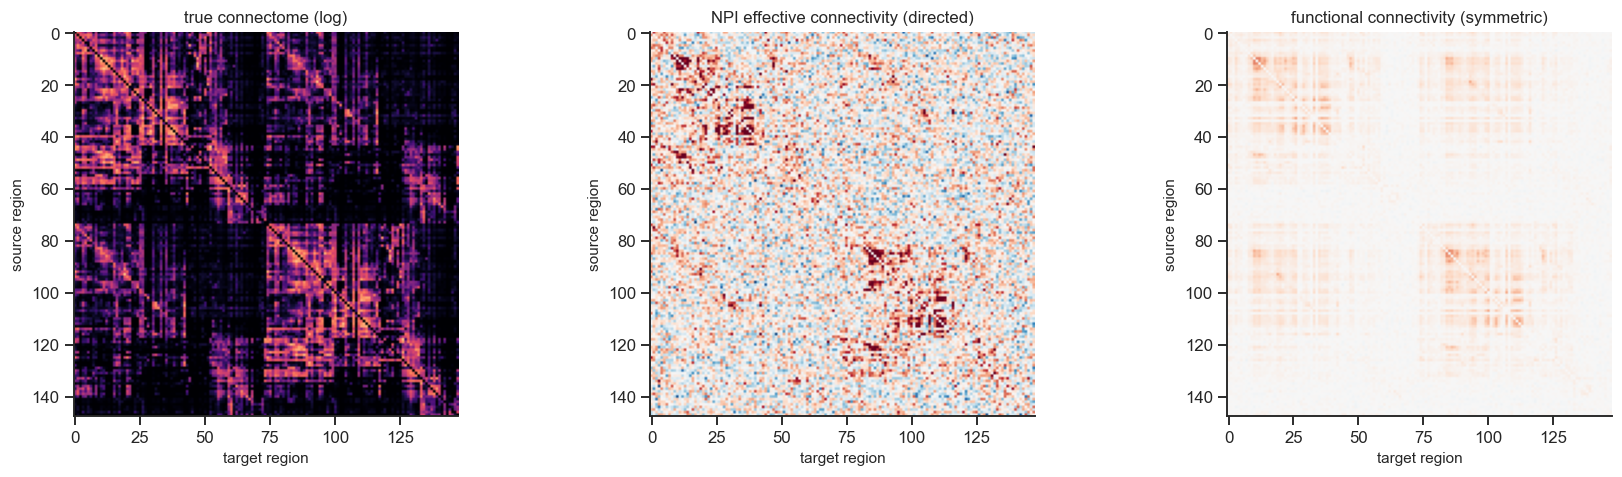

In [4]:
off = ~np.eye(N, dtype=bool)
true = W.T                                                       # true[j, i] = projection from j to i

def evaluate(EC, FC, true):
    strong = true[off] > np.percentile(true[off], 90)
    # how much larger is the inferred value on the strongest 10% of true connections than on the others?
    ratio_ec = EC[off][strong].mean() / np.abs(EC[off][~strong]).mean()
    ratio_fc = FC[off][strong].mean() / np.abs(FC[off][~strong]).mean()
    i, j = np.where(np.triu(np.ones_like(true), 1) > 0)
    asym = true[i, j] - true[j, i]; oneway = np.abs(asym) > np.percentile(np.abs(asym), 90)
    direction = np.mean(np.sign(EC[i, j] - EC[j, i])[oneway] == np.sign(asym)[oneway])
    return ratio_ec, ratio_fc, direction

FC_lin = np.corrcoef(lin.T); np.fill_diagonal(FC_lin, 0)
r_ec, r_fc, d_lin = evaluate(EC_lin, FC_lin, true)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].imshow(np.log10(true + 1e-4), cmap="magma", vmin=-4, vmax=0); ax[0].set_title("true connectome (log)")
v = np.percentile(np.abs(EC_lin), 99)
ax[1].imshow(EC_lin, cmap="RdBu_r", vmin=-v, vmax=v); ax[1].set_title("NPI effective connectivity (directed)")
ax[2].imshow(FC_lin, cmap="RdBu_r", vmin=-1, vmax=1); ax[2].set_title("functional connectivity (symmetric)")
for a_ in ax: a_.set(xlabel="target region", ylabel="source region")
plt.tight_layout()
print(f"strong connections stand out by a factor {r_ec:.1f} in NPI-EC and {r_fc:.1f} in FC")
print(f"direction of the 10% most one-way connections: NPI-EC right in {d_lin:.0%} of cases (chance: 50%; FC cannot tell)")

The surrogate was never told the wiring. Its effective connectivity separates strong from weak connections less sharply than FC
does, but it recovers their **direction** in most cases — information that FC does not contain.

Now the same test on our **bistable whole-brain model** seen through **BOLD** (six 10-minute runs at the working point of NB09).

bistable model + BOLD: strong connections stand out by 1.6 (EC) and 2.7 (FC); direction right in 46%


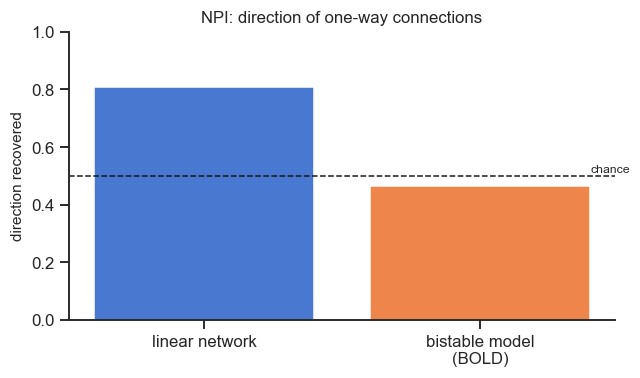

In [5]:
runs = np.load("../data/cache/nb11_bold.npz")["bold"]
Xb, Yb = make_windows(list(runs), S=3)
model_b, losses_b, n_b = train_surrogate(Xb, Yb, epochs=60)
EC_b = npi_ec(model_b, Xb[n_b:], 3, N)
FC_b = np.corrcoef(np.concatenate([(b - b.mean(0)) / b.std(0) for b in runs]).T); np.fill_diagonal(FC_b, 0)
r_ec_b, r_fc_b, d_b = evaluate(EC_b, FC_b, sc.T)
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.bar(["linear network", "bistable model\n(BOLD)"], [d_lin, d_b], color=["C0", "C1"]); ax.axhline(0.5, c="k", ls="--", lw=1)
ax.text(1.4, 0.51, "chance", fontsize=8); ax.set(ylabel="direction recovered", ylim=(0, 1), title="NPI: direction of one-way connections")
plt.tight_layout()
print(f"bistable model + BOLD: strong connections stand out by {r_ec_b:.1f} (EC) and {r_fc_b:.1f} (FC); direction right in {d_b:.0%}")

In the bistable model seen through BOLD, the direction is no longer recovered. Two reasons: regions influence each other
mostly during rare switches between down and up states, and the hemodynamic response smears timing over seconds, so the
information about *who drives whom* is largely gone from the signal before any method sees it.

**Lesson.** Inference methods must be validated on systems that resemble the data they are applied to, and their limits
reported. Luo et al. (2025) validated NPI on their own synthetic benchmarks and on real data, where its effective connectivity
agreed with structural connectivity and with cortico-cortical evoked potentials measured in patients.

## 3. Personalised surrogate brains: where, when and how to stimulate

Rabuffo, Acero-Pousa, Berjaga-Buisan & Deco (2026) trained one surrogate brain per participant, for 100 participants of the
Human Connectome Project, and stimulated every cortical region at every moment of the resting-state recording: something
impossible in real experiments.

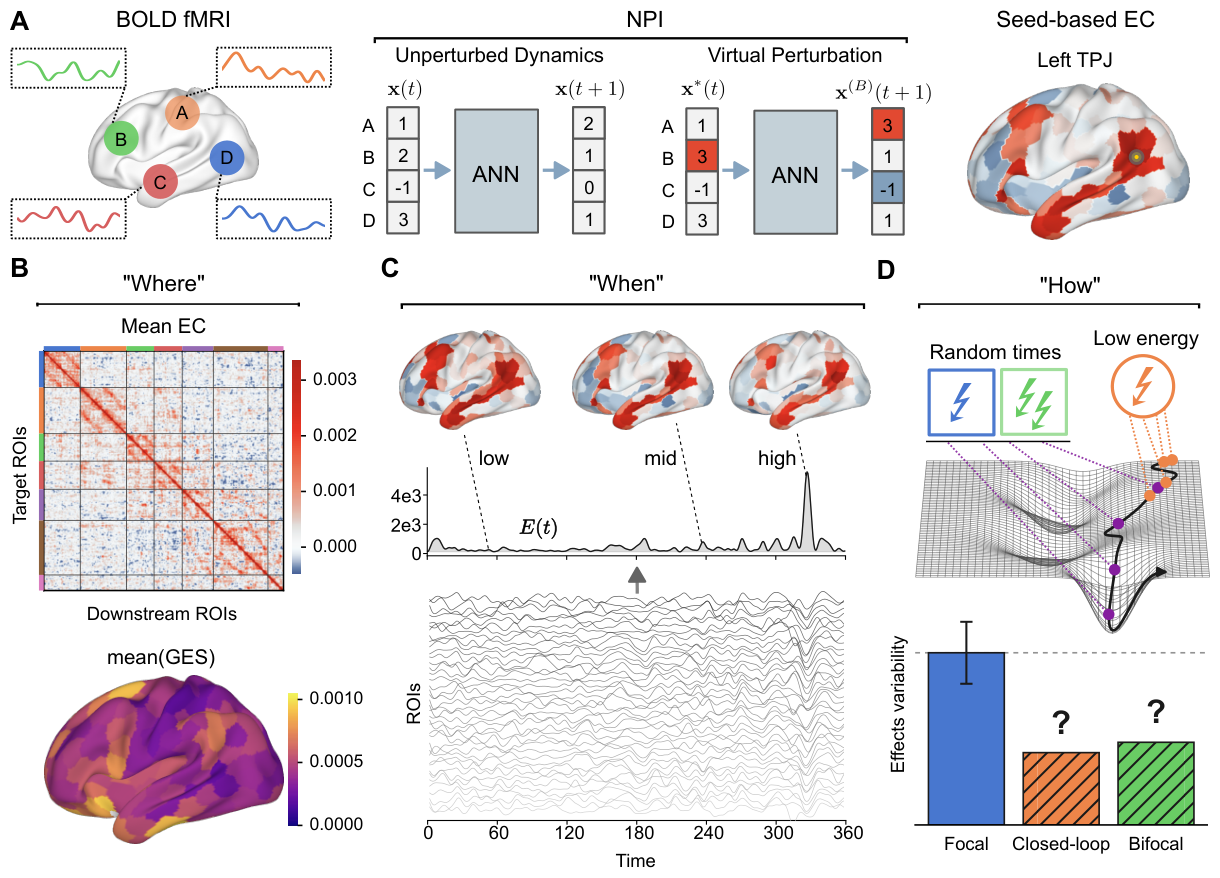

In [6]:
display(Image(f"{PAPER}/rabuffo2026_fig1.png", width=950))

**Figure 1.** (A) The surrogate brain (an ANN trained on one participant's resting-state fMRI) and the virtual perturbation;
the response to stimulating a target over the whole brain is the effective connectivity. (B–D) The three questions:
*where* (which target gives large responses), *when* (does the response depend on the brain's ongoing activity?) and *how*
(can we reduce the trial-to-trial variability of the response?).

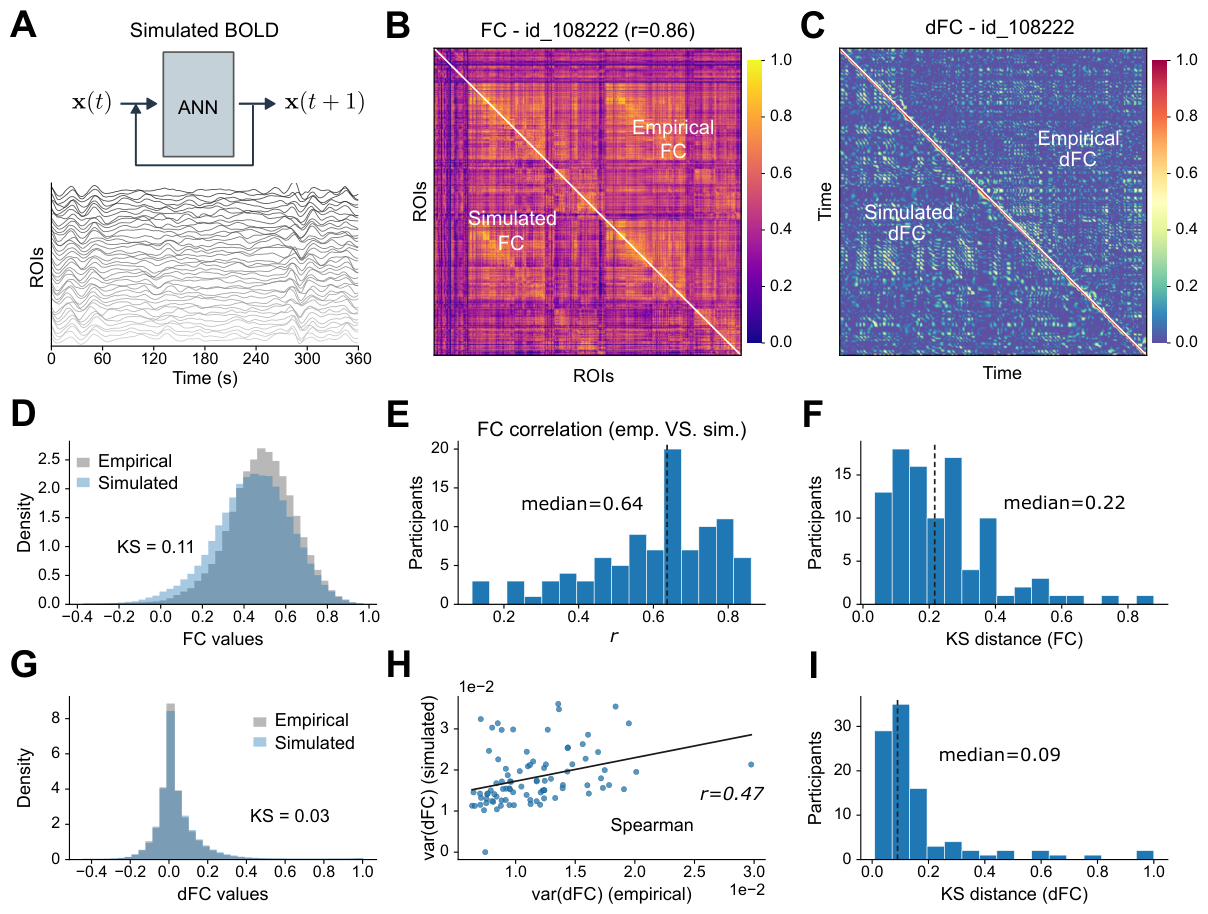

In [7]:
display(Image(f"{PAPER}/rabuffo2026_fig2.png", width=900))

**Figure 2.** A surrogate brain run on its own (each prediction fed back as input, plus a little noise) generates BOLD that
reproduces the participant's FC (r ≈ 0.86 in the example) and the distribution of its dynamic FC, across the 100
participants. The surrogate is a good map of *this* participant's resting dynamics.

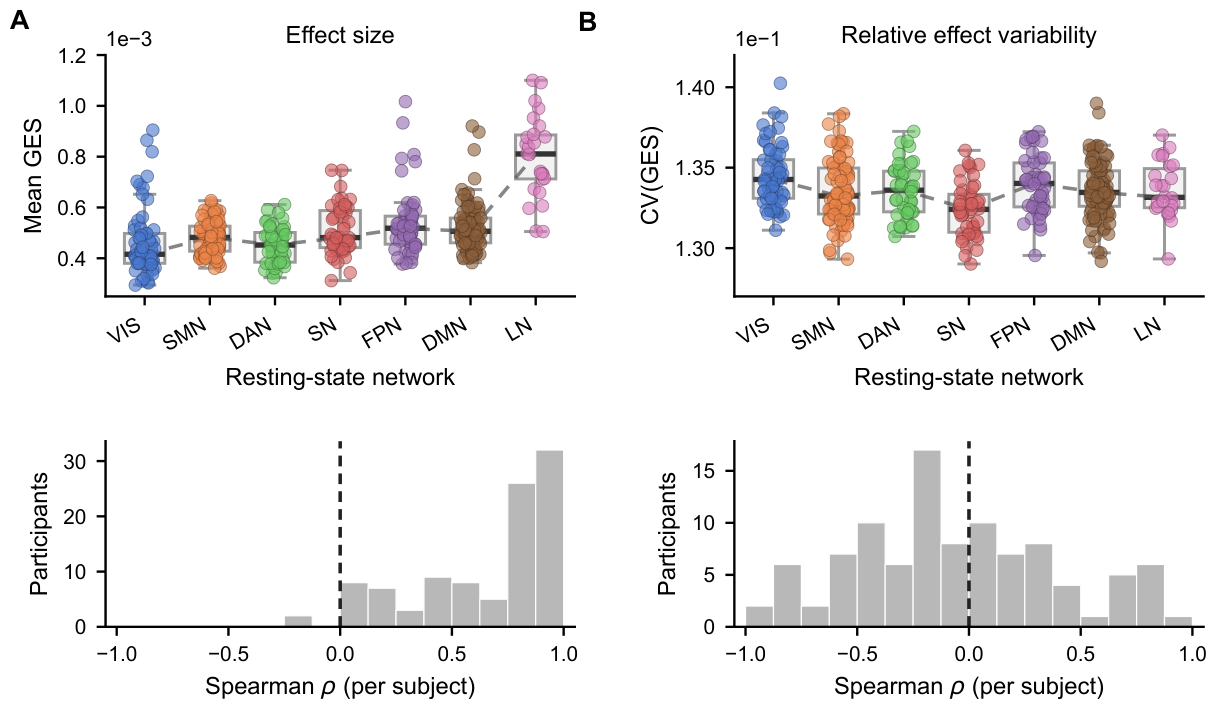

In [8]:
display(Image(f"{PAPER}/rabuffo2026_fig4.png", width=900))

**Figure 4 — where.** The size of the response grows along the cortical hierarchy, from unimodal (visual, somatomotor) to
transmodal (default-mode, limbic) regions.

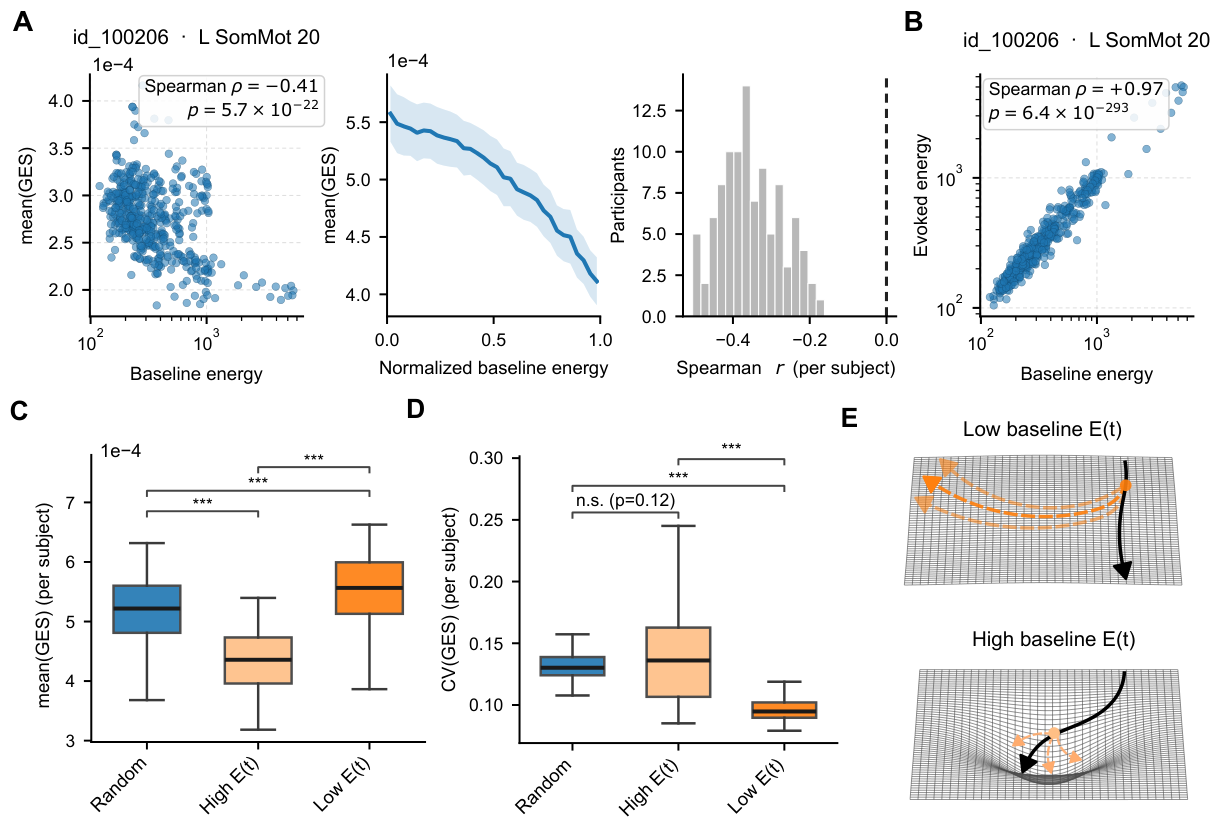

In [9]:
display(Image(f"{PAPER}/rabuffo2026_fig5.png", width=900))

**Figure 5 — when.** The same pulse to the same region gives larger responses when the brain's ongoing activity (baseline
energy) is **low**, in essentially every participant; timing stimulation to low-activity moments also makes responses more
reproducible. This is the *state dependence* we met in the mechanistic model of NB10, now in personalised data-driven models
of real brains — two very different maps telling a consistent story (robustness, Chapter 0).

## 4. Take-home

* An ANN is a flexible function learned from examples, with no biophysics inside.
* Trained to predict the next frame of brain activity, it becomes a **surrogate brain** that can be perturbed region by region:
  this gives a directed effective connectivity (NPI, Luo et al. 2025).
* Tested where the truth is known, NPI recovers the direction of strong connections in a linear network, but not in our bistable
  model seen through BOLD: validation on realistic test cases matters. On real data, personalised surrogates reproduce each
  person's FC and its dynamics.
* Virtual stimulation of 100 personalised surrogates shows that responses depend on **where** (cortical hierarchy) and **when**
  (low ongoing activity → larger, more reproducible responses).
* Mechanistic models (Chapters 1–5) explain *why*; data-driven models predict *what* for one individual. Two maps of the
  same territory, built for different questions.

### Homework
*To do at home, after the class. In class we use the **Explore** sliders; these exercises take the same
questions further and usually need a few lines of your own code.*
1. **Free-running surrogate.** Feed the network's predictions back as input (plus a little noise) for 600 steps and compare
   the FC of the generated activity with the FC of the training data.
2. **What limits recovery?** For the linear network, sample every 0.2 instead of every 1 time unit, and vary the amount of data.
   When does the direction of connections become easier or harder to recover?
3. **Linear vs nonlinear.** Replace the network by a single linear layer (a vector autoregressive model). Is its EC closer to or
   further from the truth?
4. **State dependence.** Compute the response to perturbing one region separately for input windows where the global activity is
   low and where it is high. Do you find the effect of Figure 5 in the mouse model?

### References
* Luo Z, Peng K, Liang Z, Cai S, Xu C, Li D, Hu Y, Zhou C, Liu Q (2025). Mapping effective connectivity by virtually perturbing a surrogate brain. *Nat Methods* 22:1376–1385.
* Rabuffo G, Acero-Pousa I, Berjaga-Buisan T, Deco G (2026). A personalized map of where, when, and how to stimulate the brain to elicit controlled responses. *bioRxiv* doi:10.64898/2026.07.16.738930 (code: github.com/grabuffo/ANN_Stim).
* Goodfellow I, Bengio Y, Courville A (2016). *Deep Learning*. MIT Press (free online), ch. 6.
* Matsumoto R et al. (2004). Functional connectivity in the human language system: a cortico-cortical evoked potential study. *Brain* 127:2316.